<a href="https://colab.research.google.com/github/Damian-Swaczyna/cpp/blob/master/pl/lab_auto_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium 3: Transport materiałów, przepływy w sieci i rozkrój

[![Otwórz w Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/pl/lab_auto_3.ipynb)

Laboratorium robotyki przygotowuje zestawy pokazowe. Materiały muszą dotrzeć do właściwych stanowisk, przejść przez sieć przeładunkową i zostać pocięte na potrzebne elementy. Jako planista zaproponuj plan dopuszczalny i wyjaśnij, co zmieni się po zamknięciu trasy lub wzroście zapotrzebowania.

Laboratorium 0 pokazuje tabele, pętle, funkcje i wykresy w Pythonie. Laboratoria 1 i 2 wykorzystują PuLP do alokacji i mieszania. Tutaj ten sam schemat **zmienne decyzyjne → funkcja celu → ograniczenia → rozwiązanie → sprawdzenie → interpretacja** służy decyzjom o transporcie i rozkroju.

Zbudujemy liniowe modele transportu i przepływu, odczytamy wąskie gardła kosztowe i przepustowościowe, wygenerujemy wzorce rozkroju i wyjaśnimy, dlaczego rozwiązanie ułamkowe nie jest fizycznym planem cięcia.

Wszystkie dane są zawarte w notatniku; działa on w świeżym środowisku Google Colab bez przesyłania plików.

Angielskie nazwy w danych pozostają niezmienione: `North` i `South` — magazyny północny i południowy; `Assembly` — montaż, `Test` — testowanie, `Packing` — pakowanie; `Factory` — fabryka, `Hub A` i `Hub B` — węzły przeładunkowe A i B. Dzięki temu nazwy w diagramach są zgodne z kluczami słowników w kodzie. `Optimal` oznacza znalezione rozwiązanie optymalne, a `Infeasible` — brak rozwiązania dopuszczalnego.

## 0. Przygotowanie środowiska

Uruchamiaj komórki od góry do dołu. Komórka przygotowawcza instaluje pakiety bezpośrednio w środowisku notatnika. PuLP wywołuje dołączony solver CBC; konto solvera ani klucz API nie są potrzebne. Widżety są opcjonalne: każdy eksperyment można wykonać również zwykłym wywołaniem funkcji.

In [1]:
# Zainstaluj zależności notatnika, a następnie przygotuj wykresy i solver CBC.
%pip install -q 'pulp>=3.3,<4' numpy pandas matplotlib networkx ipywidgets
%matplotlib inline

from itertools import product
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import networkx as nx
import pulp
from IPython.display import display

# Włącz opcjonalne wyświetlanie widżetów tylko w środowisku Colab.
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass  # Lokalny Jupyter nie zawiera google.colab.

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
CBC = pulp.PULP_CBC_CMD(msg=False)
if not CBC.available():
    raise RuntimeError("CBC jest niedostępny. Uruchom komórkę przygotowawczą w świeżym środowisku.")
print("PuLP", pulp.__version__, "| CBC gotowy")

PuLP 3.3.2 | CBC gotowy


## 1. Problem transportowy: który magazyn obsługuje które stanowisko?

Dwa magazyny wysyłają materiał do trzech stanowisk zrobotyzowanej komórki. Ilość materiału mierzymy w **kg**, a koszt przewozu w **PLN/kg**. Magazyny mają maksymalne dostępne ilości, a stanowiska wymagają dokładnych dostaw. Można pozostawić niewykorzystany zapas bez opłaty. Dla otwartej trasy nie zakładamy limitu przepustowości.

Przed rozwiązaniem obejrzyj tabelę kosztów: **przewidź**, który magazyn powinien obsługiwać Test. Czy wybór najtańszej trasy osobno dla każdego stanowiska może naruszyć limit zapasu magazynu?

In [2]:
# Klucze-krotki (store, station) identyfikują trasę; koszt to PLN na wysłany kg.
SUPPLY = {"North": 50, "South": 40}  # dostępne kg
DEMAND = {"Assembly": 30, "Test": 35, "Packing": 15}  # wymagane kg
COST = {("North", "Assembly"): 2, ("North", "Test"): 6,
        ("North", "Packing"): 4, ("South", "Assembly"): 5,
        ("South", "Test"): 2, ("South", "Packing"): 3}  # PLN/kg
display(pd.DataFrame({j: {i: COST[i, j] for i in SUPPLY} for j in DEMAND})
        .rename_axis("Koszt transportu (PLN/kg)"))
display(pd.Series(SUPPLY, name="Dostępne kg").to_frame())
display(pd.Series(DEMAND, name="Wymagane kg").to_frame())
print("Dostępne:", sum(SUPPLY.values()), "kg | Wymagane:", sum(DEMAND.values()), "kg")

,Assembly,Test,Packing
Koszt transportu (PLN/kg),,,
North,2,6,4
South,5,2,3


,Dostępne kg
North,50
South,40


,Wymagane kg
Assembly,30
Test,35
Packing,15


Dostępne: 90 kg | Wymagane: 80 kg


### Od opisu do równań

Niech $x_{ij}\geq0$ oznacza **kg wysłane z magazynu $i$ do stanowiska $j$**. Trasa to jedna skierowana para magazyn–stanowisko.

$$\min \sum_{(i,j)\in A} c_{ij}x_{ij}\quad\text{(PLN)}$$
$$\sum_{j:(i,j)\in A}x_{ij}\leq s_i\quad\text{dla każdego magazynu }i\quad\text{(kg)}$$
$$\sum_{i:(i,j)\in A}x_{ij}=d_j\quad\text{dla każdego stanowiska }j\quad\text{(kg)}$$

$A$ zawiera otwarte trasy. Stosujemy **≤ dla dostępności** i **= dla dokładnej dostawy**. Wymuszenie wysyłki całego zapasu każdego magazynu dałoby tutaj brak rozwiązania dopuszczalnego: dostępne jest 90 kg, ale zamówiono tylko 80 kg.

Następna komórka zawiera niewielki model PuLP zapisany krok po kroku. `lpSum` buduje wyrażenie liniowe; nie wybiera ilości. Wybiera je CBC po wywołaniu `solve`.

In [3]:
# Utwórz zmienną dla każdej trasy, a następnie limity zapasu i dokładne zamówienia stanowisk.
guided = pulp.LpProblem("Guided_transportation", pulp.LpMinimize)
x = {lane: pulp.LpVariable(f"kg_{lane[0]}_{lane[1]}", lowBound=0)
     for lane in COST}
guided += pulp.lpSum(COST[lane] * x[lane] for lane in COST), "shipping_PLN"
for store in SUPPLY:
    guided += pulp.lpSum(x[store, station] for station in DEMAND) <= SUPPLY[store]
for station in DEMAND:
    guided += pulp.lpSum(x[store, station] for store in SUPPLY) == DEMAND[station]
# Rozwiąż przed odczytem wartości; sprawdzanie statusu chroni tabelę dostaw.
guided.solve(CBC)
print("Status:", pulp.LpStatus[guided.status])
if guided.status == pulp.LpStatusOptimal:
    print("Minimalny koszt transportu:", pulp.value(guided.objective), "PLN")
    display(pd.DataFrame([{"store": i, "station": j, "kg": v.value()}
                          for (i, j), v in x.items()]))
else:
    print("Brak optymalnego planu dostaw do wyświetlenia.")

Status: Optimal
Minimalny koszt transportu: 185.0 PLN


,store,station,kg
0,North,Assembly,30.0
1,North,Test,0.0
2,North,Packing,10.0
3,South,Assembly,0.0
4,South,Test,35.0
5,South,Packing,5.0


### Użyj modelu ponownie i sprawdź wynik

Aby bezpiecznie porównywać scenariusze, buduj **nowy model dla każdego scenariusza**. Funkcja pomocnicza zwraca status, wartość funkcji celu i tabelę wysyłek. Odczytuje zmienne dopiero po znalezieniu optimum. Brak rozwiązania dopuszczalnego też jest użytecznym wynikiem: przy danych założeniach nie można zrealizować żądanych dostaw.

Sprawdzenie statusu i sprawdzenie zgodności z rzeczywistością to różne rzeczy: nawet optymalny model może źle opisywać sytuację. Poniższe asercje weryfikują limity magazynów, dokładne dostawy i obliczenie kosztu.

**Działanie funkcji:** `solve_transport` przyjmuje słowniki zapasu i zapotrzebowania oraz słownik kosztów z kluczami będącymi krotkami `(store, station)`, a opcjonalnie także krotki zamkniętych tras. Kopiuje dane, buduje i rozwiązuje nowy model, sprawdza plan i zwraca słownik wyniku. Tabela DataFrame `shipments` ma magazyny w wierszach, a stanowiska w kolumnach, co ułatwia obliczanie sum i rysowanie każdego scenariusza.

In [4]:
def solve_transport(supply=None, demand=None, costs=None, closed_lanes=()):
    """Rozwiąż scenariusz transportowy z ciągłymi ilościami wysyłek.

    supply i demand to słowniki kg indeksowane magazynami/stanowiskami; None
    korzysta z globalnych SUPPLY/DEMAND. costs przypisuje krotkom (magazyn,
    stanowisko) koszt PLN/kg; None korzysta z COST. closed_lanes domyślnie jest
    pustą kolekcją kluczy-krotek. Korzysta z globalnego CBC. Zwraca słownik
    ze status, cost (PLN), shipments (DataFrame: magazyny w wierszach,
    stanowiska w kolumnach, kg), model i kopiami danych. Cost i shipments są
    None, jeśli status nie jest Optimal. Sprawdza zapasy, zamówienia i koszt;
    nie wyświetla ani nie rysuje wyniku."""
    # Kopiuj dane scenariusza, aby eksperymenty nie zmieniały wspólnych danych bazowych.
    supply = dict(SUPPLY if supply is None else supply)
    demand = dict(DEMAND if demand is None else demand)
    costs = dict(COST if costs is None else costs)
    if any(v < 0 for v in [*supply.values(), *demand.values()]):
        raise ValueError("Zapas i zapotrzebowanie muszą być nieujemne.")
    # Klucz-krotka oznacza skierowaną trasę; usuń zamknięte trasy przed budowaniem modelu.
    closed = set(closed_lanes)
    lanes = [(i, j) for i in supply for j in demand if (i, j) not in closed]
    if any(lane not in costs for lane in lanes):
        raise ValueError("Każda otwarta trasa wymaga kosztu.")
    # Zbuduj funkcję celu i ograniczenia od nowa dla tego scenariusza.
    model = pulp.LpProblem("Transportation", pulp.LpMinimize)
    ship = {lane: pulp.LpVariable(f"ship_{k}", lowBound=0)
            for k, lane in enumerate(lanes)}
    model += pulp.lpSum(costs[lane] * ship[lane] for lane in lanes), "shipping_cost"
    for k, i in enumerate(supply):
        model += pulp.lpSum(ship[i, j] for j in demand if (i, j) in ship) <= supply[i], f"supply_{k}"
    for k, j in enumerate(demand):
        model += pulp.lpSum(ship[i, j] for i in supply if (i, j) in ship) == demand[j], f"demand_{k}"
    # Tylko wynik optymalny dostarcza ilości do kontroli zgodności z rzeczywistością.
    model.solve(CBC)
    status = pulp.LpStatus[model.status]
    result = {"status": status, "cost": None, "shipments": None, "model": model,
              "supply": supply, "demand": demand, "costs": costs, "closed_lanes": closed}
    if status != "Optimal":
        return result
    # Umieść kg na trasach w tabeli magazyn–stanowisko i sprawdź sumy.
    table = pd.DataFrame(0.0, index=list(supply), columns=list(demand))
    for lane, variable in ship.items():
        table.loc[lane[0], lane[1]] = max(0.0, variable.value())
    assert (table.sum(axis=1) <= pd.Series(supply) + 1e-6).all()
    assert np.allclose(table.sum(axis=0), pd.Series(demand), atol=1e-6)
    objective = pulp.value(model.objective)
    assert math.isclose(objective, sum(costs[lane] * table.loc[lane[0], lane[1]]
                                      for lane in lanes), abs_tol=1e-5)
    result.update(cost=objective, shipments=table)
    return result

# Rozwiąż przypadek bazowy i pokaż luz zapasu oraz reszty równań zapotrzebowania.
transport_base = solve_transport()
display(transport_base["shipments"].rename_axis("Wysłane kg"))
supply_audit = pd.DataFrame({"available_kg": pd.Series(SUPPLY),
                             "shipped_kg": transport_base["shipments"].sum(axis=1)})
supply_audit["unused_kg (slack)"] = supply_audit["available_kg"] - supply_audit["shipped_kg"]
supply_audit["binding"] = np.isclose(supply_audit["unused_kg (slack)"], 0)
display(supply_audit)
print("Reszty równań zapotrzebowania (dostarczone − zamówione, kg):")
display((transport_base["shipments"].sum(axis=0) - pd.Series(DEMAND)).to_frame("residual_kg"))
print("Minimalny koszt:", transport_base["cost"], "PLN")

,Assembly,Test,Packing
Wysłane kg,,,
North,30.0,0.0,10.0
South,0.0,35.0,5.0


,available_kg,shipped_kg,unused_kg (slack),binding
North,50,40.0,10.0,False
South,40,40.0,0.0,True


Reszty równań zapotrzebowania (dostarczone − zamówione, kg):


,residual_kg
Assembly,0.0
Test,0.0
Packing,0.0


Minimalny koszt: 185.0 PLN


### Dwa widoki tego samego planu dostaw

**Luz (niewykorzystany zasób)** ograniczenia zapasu to dostępne kg minus wysłane kg. Zerowy luz oznacza **ograniczenie aktywne** w tym rozwiązaniu. Równość zapotrzebowania ma resztę — dostarczone minus zamówione — która powinna wynosić zero; nie opisuje wolnej przepustowości. Sama aktywność nie dowodzi, że zakup dodatkowego zapasu obniży koszt. Zbadaj scenariusz i porównaj wartość funkcji celu.

Grubsze strzałki przenoszą więcej materiału. Każda otwarta trasa jest opisana jako **wysłane kg / koszt jednego kg**; linia przerywana oznacza trasę zamkniętą. Mapa cieplna pozwala porównać ilości bez śledzenia przecinających się strzałek. Zerowa wysyłka oznacza, że optymalizator nie użył trasy, a nie że trasa jest niedostępna.

**Funkcja rysująca:** przekaż wynik `solve_transport` do `plot_transport`. Funkcja sprawdza status, tworzy graf skierowany z krotek tras, rozmieszcza magazyny i stanowiska w dwóch kolumnach rysunku i pokazuje tabelę wysyłek jako mapę cieplną. Położenia zapewniają czytelność i nie oznaczają odległości geograficznych. Używaj jej po każdym eksperymencie transportowym.

Nagłówki tabel pozostają zgodne z kodem: `available_kg` — dostępny zapas, `shipped_kg` — wysłana ilość, `unused_kg (slack)` — niewykorzystany zapas, `binding` — aktywność ograniczenia, `residual_kg` — reszta równania.

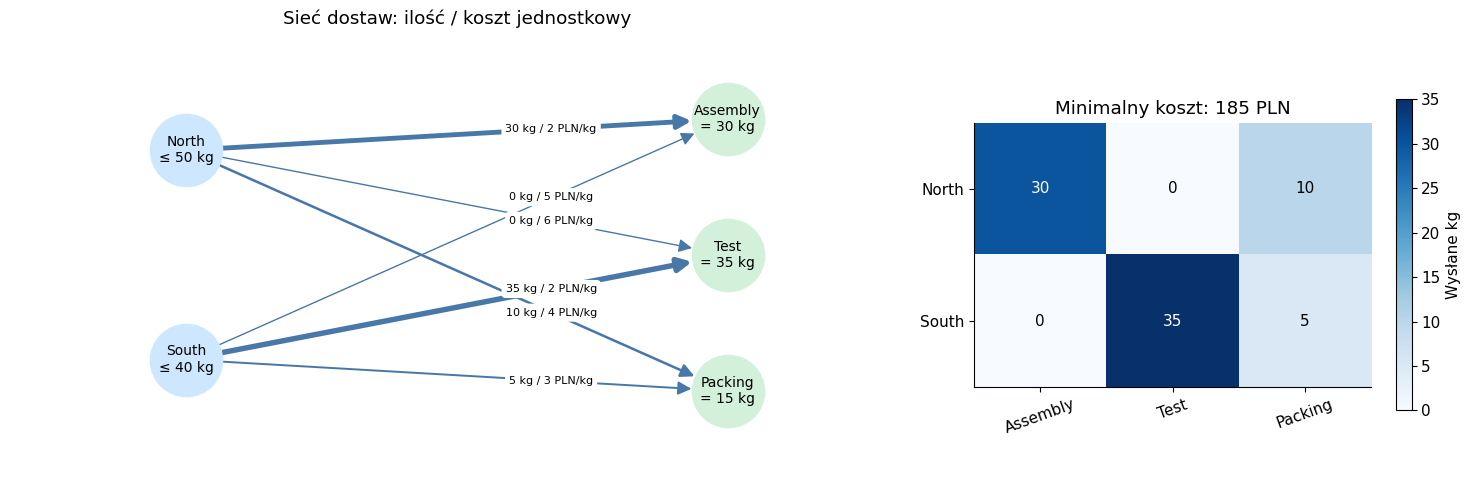

In [5]:
def plot_transport(result):
    """Wyświetl sieć dostaw i mapę cieplną wyniku solve_transport.

    result to słownik zwrócony przez solve_transport, z ilościami w kg i cenami
    tras w PLN/kg. Gdy status nie jest Optimal, wypisuje komunikat zamiast
    rysunku. Pozycje węzłów są współrzędnymi diagramu, nie odległościami;
    grubości linii opisują kg, a komórki mapy pokazują DataFrame wysyłek.
    Korzysta z globalnych nx, np i plt. Wyświetla rysunek i zwraca None."""
    # Sprawdź status, aby wartości przy braku rozwiązania dopuszczalnego nie wyglądały jak wysyłki.
    if result["status"] != "Optimal":
        print("Brak planu dopuszczalnego do narysowania. Status:", result["status"])
        return
    table = result["shipments"]
    stores, stations = list(table.index), list(table.columns)
    graph = nx.DiGraph()
    graph.add_nodes_from(stores + stations)
    graph.add_edges_from((i, j) for i in stores for j in stations)
    # Rozmieść magazyny i stanowiska w dwóch kolumnach współrzędnych rysunku.
    positions = {i: (0, y) for i, y in zip(stores, np.linspace(1, -1, len(stores)))}
    positions.update({j: (2, y) for j, y in zip(stations, np.linspace(1.3, -1.3, len(stations)))})
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.8, 1]})
    labels = {i: f"{i}\n≤ {result['supply'][i]} kg" for i in stores}
    labels.update({j: f"{j}\n= {result['demand'][j]} kg" for j in stations})
    nx.draw_networkx_nodes(graph, positions, nodelist=stores, node_color="#cce7ff", node_size=2700, ax=axes[0])
    nx.draw_networkx_nodes(graph, positions, nodelist=stations, node_color="#d3f0db", node_size=2700, ax=axes[0])
    nx.draw_networkx_labels(graph, positions, labels=labels, font_size=10, ax=axes[0])
    # Grubość opisuje użycie trasy; odróżnij trasy zamknięte od otwartych nieużywanych.
    for lane in graph.edges:
        closed = lane in result["closed_lanes"]
        value = table.loc[lane[0], lane[1]]
        nx.draw_networkx_edges(graph, positions, edgelist=[lane], ax=axes[0],
                               width=1 + value / 12, arrowsize=20, node_size=2700,
                               edge_color="#c44e52" if closed else "#4878a8",
                               style="dashed" if closed else "solid")
    edge_labels = {lane: "ZAMKNIĘTA" if lane in result["closed_lanes"] else
                   f"{table.loc[lane[0], lane[1]]:g} kg / {result['costs'][lane]:g} PLN/kg"
                   for lane in graph.edges}
    nx.draw_networkx_edge_labels(graph, positions, edge_labels=edge_labels,
                                 label_pos=0.68, font_size=8, rotate=False, ax=axes[0])
    axes[0].set_title("Sieć dostaw: ilość / koszt jednostkowy")
    axes[0].margins(0.25)
    axes[0].axis("off")
    # Pokaż te same ilości wysyłek jako podpisaną macierz.
    heat = axes[1].imshow(table.to_numpy(), cmap="Blues", vmin=0)
    axes[1].set_xticks(range(len(stations)), stations, rotation=20)
    axes[1].set_yticks(range(len(stores)), stores)
    for row in range(len(stores)):
        for col in range(len(stations)):
            axes[1].text(col, row, f"{table.iloc[row, col]:g}", ha="center", va="center",
                         color="white" if table.iloc[row, col] > table.to_numpy().max() / 2 else "black")
    fig.colorbar(heat, ax=axes[1], shrink=0.7, label="Wysłane kg")
    axes[1].set_title(f"Minimalny koszt: {result['cost']:g} PLN")
    plt.tight_layout()
    plt.show()

plot_transport(transport_base)

### Zadanie 1 — zamknij trasę i zwiększ zapotrzebowanie

**Przewidź:** Co stanie się z kosztem po zamknięciu South → Test? Czy zamknięcie trasy może obniżyć koszt optymalny, jeśli pozostałe dane się nie zmieniają?

Uruchom poniższe porównania. Większe zapotrzebowanie Assembly również sprawdza dopuszczalność. Łączny zapas ≥ łączne zapotrzebowanie to warunek konieczny, ale przy brakujących trasach nie zawsze wystarczający.

**Zapisz:** scenariusz, zmieniony parametr, status, zmianę kosztu i jedną zmienioną wysyłkę. **Rekomendacja:** które zakłócenie wymaga nowego dostawcy, a nie tylko zmiany tras?

Nazwy scenariuszy w słowniku pozostają kluczami kodu: `Base` — wariant bazowy, `South–Test closed` — zamknięta trasa South–Test, `Assembly needs 55 kg` — zapotrzebowanie Assembly równe 55 kg, `Both Assembly lanes closed` — obie trasy do Assembly zamknięte.

,scenario,status,cost_PLN
0,Base,Optimal,185.0
1,South–Test closed,Optimal,360.0
2,Assembly needs 55 kg,Infeasible,NaN
3,Both Assembly lanes closed,Infeasible,NaN


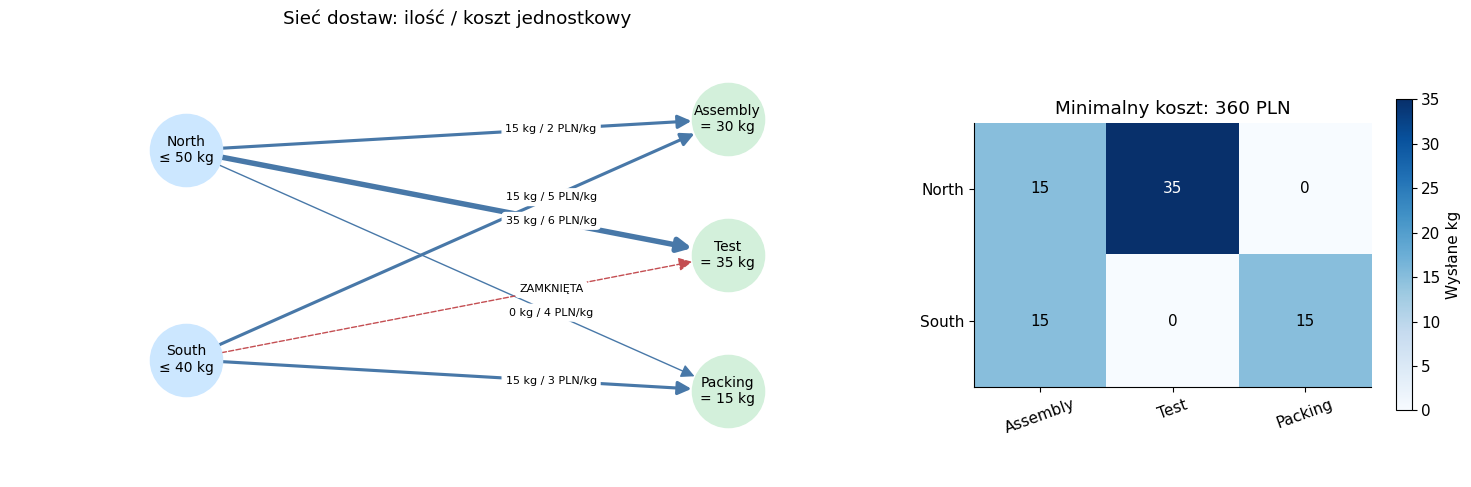

Brak planu dopuszczalnego do narysowania. Status: Infeasible


In [6]:
# Zachowaj wyniki wszystkich scenariuszy, także bez rozwiązania dopuszczalnego, w jednej tabeli.
transport_scenarios = {
    "Base": transport_base,
    "South–Test closed": solve_transport(closed_lanes=[("South", "Test")]),
    "Assembly needs 55 kg": solve_transport(demand={**DEMAND, "Assembly": 55}),
    "Both Assembly lanes closed": solve_transport(closed_lanes=[("North", "Assembly"), ("South", "Assembly")]),
}
display(pd.DataFrame([{"scenario": name, "status": result["status"], "cost_PLN": result["cost"]}
                      for name, result in transport_scenarios.items()]))
plot_transport(transport_scenarios["South–Test closed"])
plot_transport(transport_scenarios["Assembly needs 55 kg"])

Mój scenariusz: Optimal | koszt: 205.0


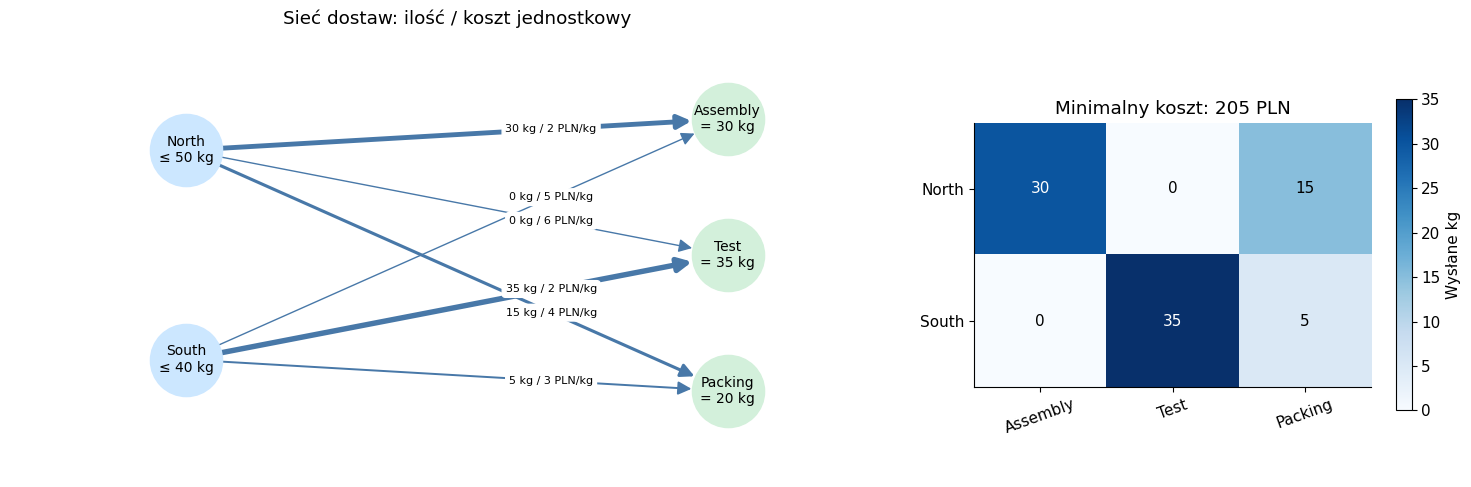

In [7]:
# Miejsce eksperymentu: zmień JEDNO założenie i uruchom ponownie.
my_transport = solve_transport(demand={**DEMAND, "Packing": 20})
print("Mój scenariusz:", my_transport["status"], "| koszt:", my_transport["cost"])
plot_transport(my_transport)
# DO ZROBIENIA: zmieniaj zapotrzebowanie Packing od 5 do 35 kg i narysuj koszt w funkcji popytu,
# a przypadki bez rozwiązania dopuszczalnego oznacz osobno (None nie oznacza kosztu zero).

## 2. Przepływ w sieci: dodaj przeładunki i przepustowości tras

Komórka otrzymuje teraz 80 kg z jednej fabryki przez dwa węzły przeładunkowe. Dostawa może przejść przez kilka łuków, zanim dotrze do stanowiska. Każdy łuk ma **przepustowość (kg)** i **koszt przeładunku lub transportu (PLN/kg)**. Przepływ może rozdzielać się w węźle; model opisuje podzielny materiał, a nie niepodzielną trasę jednej ciężarówki.

Problem transportowy miał sieć dwuwarstwową. Dodanie węzłów pośrednich i przepustowości łuków prowadzi do modelu **przepływu o minimalnym koszcie**. Rozwiązujemy rzeczywisty model LP na grafie; diagram przedstawia jego zmienne decyzyjne.

Niech $f_{uv}$ oznacza kg na łuku $u\to v$, ograniczone przepustowością $U_{uv}$. Niech $b_v$ oznacza podaż netto: **dodatnią w źródle, zerową w przeładunkach i ujemną na stanowiskach zużywających materiał**.

$$\min \sum_{(u,v)\in A}c_{uv}f_{uv}\qquad 0\leq f_{uv}\leq U_{uv}$$
$$\sum_{w:(v,w)\in A}f_{vw}-\sum_{u:(u,v)\in A}f_{uv}=b_v\quad\text{w KAŻDYM węźle}$$

Przyjęty znak to **wypływ − dopływ**. W węźle przeładunkowym różnica wynosi 0: materiał nie pojawia się ani nie znika. Dla Test wynosi −35: zużywane jest 35 kg. W tym przykładzie podaż źródła jest dokładnie równa potrzebnym 80 kg; w odróżnieniu od części 1 nie ma opcjonalnego zapasu pozostającego w sieci. Sprawdź, że $\sum_v b_v=0$.

In [8]:
# Podaż netto to wypływ minus dopływ: źródła mają znak dodatni, odbiorcy ujemny.
BALANCE = {"Factory": 80, "Hub A": 0, "Hub B": 0,
           "Assembly": -30, "Test": -35, "Packing": -15}
# Wartość słownika: (przepustowość kg, koszt PLN/kg).
ARCS = {("Factory", "Hub A"): (50, 1), ("Factory", "Hub B"): (40, 1),
        ("Hub A", "Assembly"): (40, 1), ("Hub A", "Test"): (40, 5),
        ("Hub A", "Packing"): (30, 3), ("Hub B", "Assembly"): (30, 4),
        ("Hub B", "Test"): (40, 1), ("Hub B", "Packing"): (30, 2)}
display(pd.DataFrame([{"from": u, "to": v, "capacity_kg": cap, "cost_PLN_per_kg": cost}
                      for (u, v), (cap, cost) in ARCS.items()]))
print("Łączna podaż netto:", sum(BALANCE.values()), "kg")

,from,to,capacity_kg,cost_PLN_per_kg
0,Factory,Hub A,50,1
1,Factory,Hub B,40,1
2,Hub A,Assembly,40,1
3,Hub A,Test,40,5
4,Hub A,Packing,30,3
5,Hub B,Assembly,30,4
6,Hub B,Test,40,1
7,Hub B,Packing,30,2


Łączna podaż netto: 0 kg


### Solver przepływu wielokrotnego użytku

`solve_flow(arcs, balance)` przyjmuje słownik łuków z kluczami będącymi krotkami `(from_node, to_node)` oraz słownik podaży netto węzłów. Wartość każdego łuku to `(capacity_kg, cost_PLN_per_kg)`. Funkcja sprawdza dane, tworzy ograniczone przepływy i równania zachowania, rozwiązuje model przez CBC i weryfikuje wynik. Zwrócony słownik zawiera odwzorowanie `flows` od łuków do kg, koszt, status i model; używaj go w scenariuszach przepustowości i zamieniaj na DataFrame, gdy potrzebujesz czytelnej tabeli łuków.

W tabelach `flow_kg` oznacza przepływ, `capacity_kg` — przepustowość, `remaining_capacity_kg` — wolną przepustowość, `outflow_kg` — wypływ, `inflow_kg` — dopływ, `net_supply_kg` — podaż netto, a `equality_residual_kg` — resztę równania zachowania.

In [9]:
def solve_flow(arcs=None, balance=None):
    """Rozwiąż ciągły przepływ o minimalnym koszcie z bilansem w każdym węźle.

    arcs przypisuje krotkom (węzeł początkowy, końcowy) pary (przepustowość kg,
    koszt PLN/kg); None używa globalnego ARCS. balance przypisuje węzłom podaż
    netto w kg (wypływ minus dopływ); None używa BALANCE. Korzysta z globalnego
    CBC. Zwraca słownik status, cost (PLN), flows (odwzorowanie łuków na kg),
    model i kopie danych. Cost i flows pozostają None, jeśli status nie jest
    Optimal. Sprawdza bilanse, przepustowości i rozwiązane równania zachowania;
    nie wyświetla ani nie rysuje wyniku."""
    # Skopiuj dane i sprawdź, czy każdy węzeł ma dane do równania zachowania.
    arcs = dict(ARCS if arcs is None else arcs)
    balance = dict(BALANCE if balance is None else balance)
    if not math.isclose(sum(balance.values()), 0, abs_tol=1e-8):
        raise ValueError("Suma podaży netto musi wynosić zero.")
    if any(cap < 0 for cap, cost in arcs.values()):
        raise ValueError("Przepustowości łuków muszą być nieujemne.")
    if any(u not in balance or v not in balance for u, v in arcs):
        raise ValueError("Każdy koniec łuku musi mieć podany bilans węzła.")
    # Utwórz ograniczoną zmienną ciągłą dla każdego łuku i równość dla każdego węzła.
    model = pulp.LpProblem("Minimum_cost_flow", pulp.LpMinimize)
    flow = {arc: pulp.LpVariable(f"flow_{k}", lowBound=0, upBound=arcs[arc][0])
            for k, arc in enumerate(arcs)}
    model += pulp.lpSum(arcs[arc][1] * flow[arc] for arc in arcs), "cost_PLN"
    for k, node in enumerate(balance):
        outgoing = pulp.lpSum(flow[u, v] for u, v in arcs if u == node)
        incoming = pulp.lpSum(flow[u, v] for u, v in arcs if v == node)
        model += outgoing - incoming == balance[node], f"conservation_{k}"
    # Najpierw rozwiąż; przy braku optimum zwróć tylko status i dane wejściowe.
    model.solve(CBC)
    status = pulp.LpStatus[model.status]
    result = {"status": status, "cost": None, "flows": None,
              "model": model, "arcs": arcs, "balance": balance}
    if status != "Optimal":
        return result
    # Sprawdź zachowanie w każdym węźle i przepustowości łuków na obliczonych kg.
    values = {arc: max(0.0, variable.value()) for arc, variable in flow.items()}
    for node, required in balance.items():
        net = sum(value for (u, v), value in values.items() if u == node) - sum(
                  value for (u, v), value in values.items() if v == node)
        assert math.isclose(net, required, abs_tol=1e-6)
    assert all(-1e-6 <= values[arc] <= arcs[arc][0] + 1e-6 for arc in arcs)
    result.update(cost=pulp.value(model.objective), flows=values)
    return result

# Pokaż wolne przepustowości i jawną kontrolę bilansu wypływ minus dopływ.
flow_base = solve_flow()
print("Status:", flow_base["status"], "| Minimalny koszt:", flow_base["cost"], "PLN")
if flow_base["status"] == "Optimal":
    display(pd.DataFrame([{"from": u, "to": v, "flow_kg": value,
                           "capacity_kg": ARCS[u, v][0],
                           "remaining_capacity_kg": ARCS[u, v][0] - value}
                          for (u, v), value in flow_base["flows"].items()]))
    conservation_audit = []
    for node, required in BALANCE.items():
        outgoing = sum(f for (u, v), f in flow_base["flows"].items() if u == node)
        incoming = sum(f for (u, v), f in flow_base["flows"].items() if v == node)
        conservation_audit.append({"node": node, "outflow_kg": outgoing,
                                   "inflow_kg": incoming, "net_supply_kg": required,
                                   "equality_residual_kg": outgoing - incoming - required})
    display(pd.DataFrame(conservation_audit))

Status: Optimal | Minimalny koszt: 185.0 PLN


,from,to,flow_kg,capacity_kg,remaining_capacity_kg
0,Factory,Hub A,40.0,50,10.0
1,Factory,Hub B,40.0,40,0.0
2,Hub A,Assembly,30.0,40,10.0
3,Hub A,Test,0.0,40,40.0
4,Hub A,Packing,10.0,30,20.0
5,Hub B,Assembly,0.0,30,30.0
6,Hub B,Test,35.0,40,5.0
7,Hub B,Packing,5.0,30,25.0


,node,outflow_kg,inflow_kg,net_supply_kg,equality_residual_kg
0,Factory,80.0,0.0,80,0.0
1,Hub A,40.0,40.0,0,0.0
2,Hub B,40.0,40.0,0,0.0
3,Assembly,0.0,30.0,-30,0.0
4,Test,0.0,35.0,-35,0.0
5,Packing,0.0,15.0,-15,0.0


### Odczytaj diagram wąskich gardeł

Etykiety łuków pokazują **przepływ / przepustowość w kg**. Czerwone łuki wykorzystują pełną przepustowość; cienkie szare są nieużywane. Zwiększenie przepustowości nasyconego łuku nie musi być opłacalne: dodatkowy materiał musi mieć także użyteczną, tańszą ścieżkę. Porównaj funkcję celu scenariuszy, aby zbadać efekt ekonomiczny.

**Funkcja rysująca:** `plot_flow(result)` odczytuje rozwiązane przepływy i bilanse węzłów, rysuje sześć przykładowych węzłów w jawnych pozycjach `(x, y)` i podpisuje ilości, przepustowości oraz koszty. Nie zwraca danych; do obliczeń wykorzystaj słownik liczbowego wyniku. Dodaj pozycje, jeśli rozszerzasz sieć o nowe węzły.

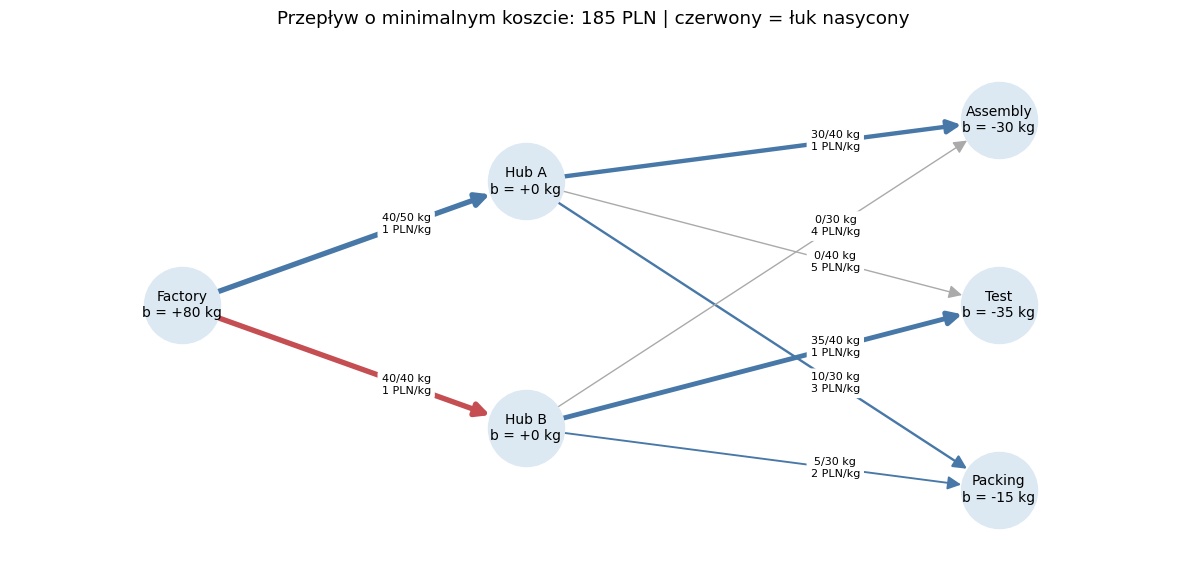

In [10]:
def plot_flow(result):
    """Wyświetl diagram przepustowości słownika wyniku solve_flow.

    Przepływy i przepustowości łuków są w kg, a koszty w PLN/kg. Wynik bez
    optimum powoduje wypisanie komunikatu. Stałe pozycje rysowania obejmują
    sześć przykładowych węzłów; rozszerz pos po dodaniu węzła. Czerwony kolor
    oznacza łuk nasycony, a grubość — przepływ. Korzysta z globalnych nx i plt;
    wyświetla rysunek i zwraca None."""
    if result["status"] != "Optimal":
        print("Brak dopuszczalnego przepływu do narysowania. Status:", result["status"])
        return
    # Zbuduj graf z kluczy łuków modelu, a następnie rozmieść węzły dla czytelności.
    graph = nx.DiGraph()
    graph.add_nodes_from(result["balance"])
    graph.add_edges_from(result["arcs"])
    pos = {"Factory": (0, 0), "Hub A": (1.6, 1), "Hub B": (1.6, -1),
           "Assembly": (3.8, 1.5), "Test": (3.8, 0), "Packing": (3.8, -1.5)}
    fig, ax = plt.subplots(figsize=(12, 6))
    labels = {node: f"{node}\nb = {b:+g} kg" for node, b in result["balance"].items()}
    nx.draw_networkx_nodes(graph, pos, node_color="#dce9f3", node_size=3000, ax=ax)
    nx.draw_networkx_labels(graph, pos, labels=labels, font_size=10, ax=ax)
    # Porównaj przepływ z przepustowością, aby wyróżnić nasycone łuki; grubości opisują kg.
    for arc, (cap, cost) in result["arcs"].items():
        value = result["flows"][arc]
        color = "#c44e52" if abs(value - cap) < 1e-6 else ("#4878a8" if value > 1e-6 else "#aaaaaa")
        nx.draw_networkx_edges(graph, pos, edgelist=[arc], edge_color=color,
                               width=1 + value / 14, node_size=3000, arrowsize=20, ax=ax)
    edge_labels = {arc: f"{result['flows'][arc]:g}/{cap:g} kg\n{cost:g} PLN/kg"
                   for arc, (cap, cost) in result["arcs"].items()}
    nx.draw_networkx_edge_labels(graph, pos, edge_labels=edge_labels,
                                 label_pos=0.66, rotate=False, font_size=8, ax=ax)
    ax.set_title(f"Przepływ o minimalnym koszcie: {result['cost']:g} PLN | czerwony = łuk nasycony")
    ax.margins(0.18)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

plot_flow(flow_base)

### Zadanie 2 — ogranicz tańszy węzeł przeładunkowy

**Przewidź:** jeśli przepustowość Factory → Hub B spadnie z 40 do 30 kg, czy komórka nadal może otrzymać całe 80 kg? Który przepływ musi wzrosnąć? Co stanie się przy 20 kg?

Wyjaśnij dopuszczalność za pomocą **przekroju**: narysuj linię oddzielającą Factory od pozostałych węzłów. Suma przepustowości łuków wychodzących przez tę linię musi wynosić co najmniej 80 kg. Pozwala to ręcznie sprawdzić te scenariusze bez uruchamiania CBC.

**Zapisz:** przepustowość, status solvera, koszt i nowe nasycone łuki. **Rekomendacja:** czy laboratorium powinno zapłacić 20 PLN za zmianę roboczą, aby przywrócić przepustowość Hub B z 30 do 40 kg? Porównaj dopłatę z oszczędnością kosztu transportu.

**Funkcja scenariusza:** `flow_with_hub_b_capacity(capacity)` przyjmuje jedną przepustowość w kg, kopiuje wspólną tabelę łuków, zmienia limit Factory → Hub B i wywołuje `solve_flow`. Zwraca ten sam słownik wyniku, więc pojedyncze wywołanie, pętla porównań i wykres korzystają z tej samej konstrukcji modelu.

,Hub_B_capacity_kg,status,cost_PLN
0,40,Optimal,185.0
1,30,Optimal,210.0
2,20,Infeasible,NaN


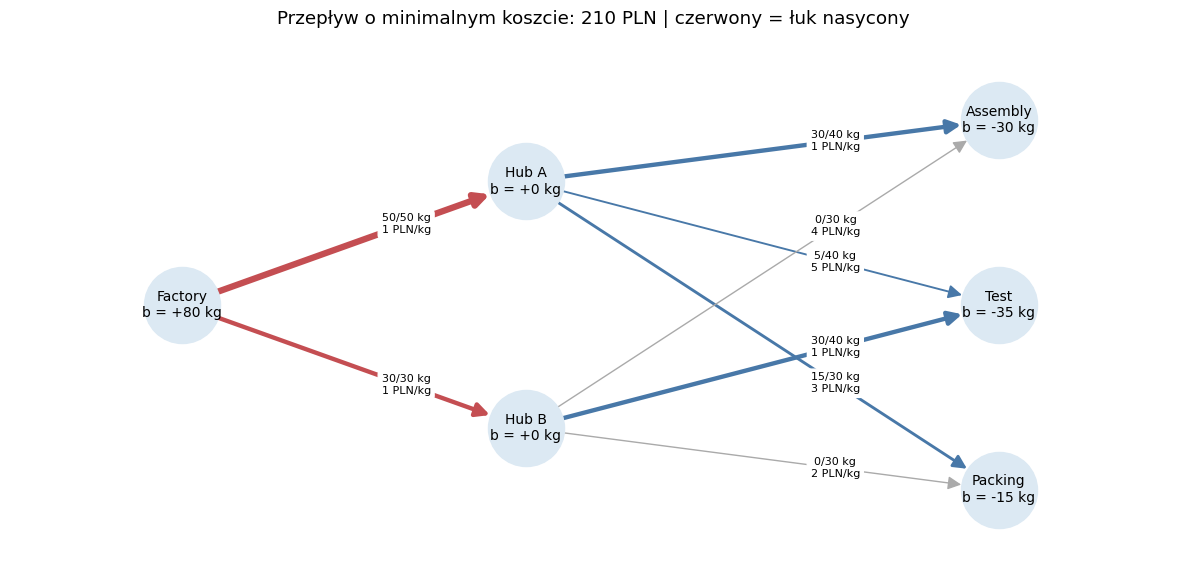

Brak dopuszczalnego przepływu do narysowania. Status: Infeasible


In [11]:
def flow_with_hub_b_capacity(capacity):
    """Rozwiąż przykładową sieć po zmianie limitu Factory → Hub B w kg.

    capacity zastępuje tylko przepustowość tego łuku w kopii globalnego ARCS,
    zachowując koszt PLN/kg. Korzysta z solve_flow oraz jego domyślnych
    zależności BALANCE/CBC. Zwraca ten sam słownik z kontrolą statusu co
    solve_flow; niczego nie wyświetla."""
    # Skopiuj tabelę łuków i zmień tylko wybraną przepustowość, zachowując koszty.
    changed = dict(ARCS)
    changed["Factory", "Hub B"] = (capacity, ARCS["Factory", "Hub B"][1])
    return solve_flow(arcs=changed)

# Użyj tej samej funkcji dla eksperymentów dopuszczalnych i niedopuszczalnych.
flow_scenarios = {capacity: flow_with_hub_b_capacity(capacity) for capacity in [40, 30, 20]}
display(pd.DataFrame([{"Hub_B_capacity_kg": capacity, "status": result["status"],
                      "cost_PLN": result["cost"]}
                     for capacity, result in flow_scenarios.items()]))
plot_flow(flow_scenarios[30])
plot_flow(flow_scenarios[20])

,capacity_kg,status,cost_PLN
0,15,Infeasible,NaN
1,20,Infeasible,NaN
2,25,Infeasible,NaN
3,30,Optimal,210.0
4,35,Optimal,190.0
5,40,Optimal,185.0
6,45,Optimal,180.0
7,50,Optimal,175.0
8,55,Optimal,175.0


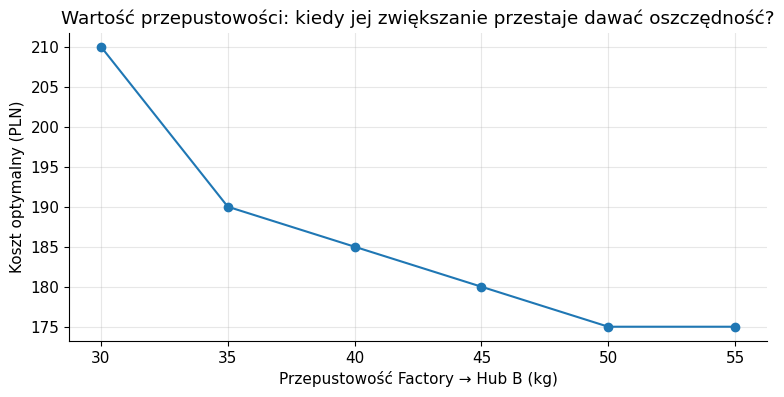

In [12]:
# Seria eksperymentów: przy braku rozwiązania dopuszczalnego koszt pozostaje NaN.
capacity_sweep = pd.DataFrame([
    {"capacity_kg": capacity, "status": (r := flow_with_hub_b_capacity(capacity))["status"],
     "cost_PLN": r["cost"]}
    for capacity in range(15, 56, 5)
])
display(capacity_sweep)
ax = capacity_sweep.plot(x="capacity_kg", y="cost_PLN", marker="o", legend=False)
ax.set(xlabel="Przepustowość Factory → Hub B (kg)", ylabel="Koszt optymalny (PLN)",
       title="Wartość przepustowości: kiedy jej zwiększanie przestaje dawać oszczędność?")
ax.grid(alpha=0.3)
plt.show()
# DO ZROBIENIA: zmieniaj zamiast tego przepustowość Hub B → Test i porównaj krzywą kosztu.
# DO ZROBIENIA: dodaj łuk przeładunku A → B i wyjaśnij, czy poprawia wynik sieci.

## 3. Problem rozkroju: ile całych prętów trzeba kupić?

Robot budujący ramy potrzebuje odcinków o trzech długościach: **6, 4 i 3 jednostki długości**. Nowe pręty mają długość 10 jednostek. Zamówienie obejmuje odpowiednio 3, 3 i 4 odcinki. Aby rachunki były przejrzyste, zakładamy **zerowy rzaz piły**, brak ponownego użycia resztek, identyczne nowe pręty i możliwość wykonania dodatkowych odcinków. To założenia dydaktyczne, a nie kompletny proces wytwarzania.

**Wzorzec rozkroju** opisuje cięcie JEDNEGO pręta. Na przykład `(1, 1, 0)` oznacza jeden odcinek długości 6, jeden długości 4 i żadnego długości 3. Mieści się dokładnie: $6+4=10$. `(0, 1, 2)` również mieści się dokładnie: $4+3+3=10$.

**Przewidź:** zamówiony materiał ma łącznie $3(6)+3(4)+4(3)=42$ jednostki długości. Czy $\lceil42/10\rceil=5$ gwarantuje plan z pięciu prętów? Dlaczego długości odcinków mogą sprawić, że granica wynikająca z samej ilości materiału jest zbyt optymistyczna?

Wyliczymy **wszystkie niepuste wzorce, które mieszczą się w pręcie**, także wzorce z niewykorzystanym miejscem. Przy trzech typach odcinków jest ich na tyle mało, że można je obejrzeć. Duże zadania przemysłowe wymagają bardziej zaawansowanego generowania wzorców.

**Funkcja wzorców:** `enumerate_patterns(stock_length, lengths)` przyjmuje dodatnie całkowite długości w tej samej jednostce i zwraca krotki liczby odcinków w kolejności `lengths`. Ogranicza każdą liczbę, łączy wszystkie możliwości przez `itertools.product` i zachowuje niepuste wzorce mieszczące się w pręcie. Poniższy DataFrame zamienia krotki na podpisane kolumny liczby odcinków, wykorzystanej długości i odpadu do obejrzenia.

`pattern_id` to numer wzorca, `pieces_6`, `pieces_4` i `pieces_3` to liczby odcinków danej długości, `used_length` — wykorzystana długość, a `trim_per_bar` — odpad z jednego pręta.

In [13]:
# Wszystkie długości mają wspólną jednostkę; pozycje krotek łączą długości z zapotrzebowaniem.
PIECE_LENGTHS = (6, 4, 3)
PIECE_DEMAND = (3, 3, 4)
STOCK_LENGTH = 10

def enumerate_patterns(stock_length, lengths):
    """Zwróć wszystkie niepuste całkowite wzorce mieszczące się w jednym pręcie.

    stock_length i każda wartość lengths muszą być dodatnimi liczbami
    całkowitymi w tej samej jednostce długości. Kolejność zwróconej krotki
    odpowiada lengths; wartości są liczbami odcinków, nie ich długościami.
    Przy zerowym rzazie zachowaj kombinacje o łącznej długości nie większej
    niż stock_length. Korzysta z itertools.product; nie wymaga solvera,
    globalnych danych projektu ani wyświetlania."""
    if not isinstance(stock_length, int) or stock_length <= 0:
        raise ValueError("Długość pręta musi być dodatnią liczbą całkowitą.")
    if not lengths or any(not isinstance(length, int) or length <= 0 for length in lengths):
        raise ValueError("Długości odcinków muszą być dodatnimi liczbami całkowitymi.")
    # Liczba odcinków ma skończoną granicę; product sprawdza każdą kombinację liczebności.
    ranges = [range(stock_length // length + 1) for length in lengths]
    return [counts for counts in product(*ranges)
            if any(counts) and sum(n * length for n, length in zip(counts, lengths)) <= stock_length]

# Zamień krotki liczebności na tabelę wykorzystanej długości i odpadu dla każdego wzorca.
patterns = enumerate_patterns(STOCK_LENGTH, PIECE_LENGTHS)
pattern_table = pd.DataFrame(patterns, columns=[f"pieces_{length}" for length in PIECE_LENGTHS])
pattern_table.index.name = "pattern_id"
pattern_table["used_length"] = [sum(n * length for n, length in zip(p, PIECE_LENGTHS)) for p in patterns]
pattern_table["trim_per_bar"] = STOCK_LENGTH - pattern_table["used_length"]
display(pattern_table)
print("Liczba pasujących niepustych wzorców:", len(patterns))

,pieces_6,pieces_4,pieces_3,used_length,trim_per_bar
pattern_id,,,,,
0,0,0,1,3,7
1,0,0,2,6,4
2,0,0,3,9,1
3,0,1,0,4,6
4,0,1,1,7,3
5,0,1,2,10,0
6,0,2,0,8,2
7,1,0,0,6,4
8,1,0,1,9,1


Liczba pasujących niepustych wzorców: 10


### Od wzorców cięcia do modelu całkowitoliczbowego

Niech $y_p$ oznacza **liczbę całych prętów ciętych według wzorca $p$**, a $a_{ip}$ — liczbę odcinków typu $i$ w jednym użyciu wzorca.

$$\min\sum_p y_p\quad\text{(pręty)}$$
$$\sum_p a_{ip}y_p\geq d_i\quad\text{dla każdego typu odcinka }i\quad\text{(sztuki)}$$
$$y_p\in\{0,1,2,\ldots\}$$

**Dlaczego ≥?** Dopuszczamy nadprodukcję: niektóre wzorce mogą wytworzyć dodatkowy użyteczny odcinek przy minimalnej liczbie prętów. Jeśli dodatkowe sztuki są zabronione, zamień każde ograniczenie pokrycia zapotrzebowania na równość i rozwiąż model ponownie; nie usuwaj po prostu sztuk ze zwróconego planu.

**Co minimalizujemy?** Liczbę zakupionych prętów, a nie sam odpad. Dodatkowe odcinki też zużywają materiał, więc mały odpad nie musi oznaczać braku materiału ponad zamówienie. Gdy istnieje kilka planów optymalnych, CBC może wybrać dowolny z nich.

**Relaksacja LP** dopuszcza ułamkowe $y_p$. Daje dolną granicę potrzebnej liczby prętów, ale ułamki wzorców nie opisują fizycznego planu. Rozwiąż model całkowitoliczbowy osobno: zaokrąglanie każdej zmiennej ułamkowej może prowadzić do zakupu nadmiaru prętów, a zaokrąglanie w dół — do niezaspokojenia popytu. Nawet zaokrąglenie funkcji celu w górę jest jedynie dolną granicą, a nie konstrukcją planu dopuszczalnego.

**Funkcja solvera:** `solve_cutting` przyjmuje długość pręta, długości odcinków, zapotrzebowanie i przełączniki całkowitoliczbowości oraz dokładnego pokrycia. Generuje wzorce na nowo, buduje ograniczenia pokrycia, rozwiązuje model i sprawdza produkcję oraz bilans materiału. Zwraca słownik z tabelą `plan` zawierającą tylko użyte wzorce; `produced` zlicza każdy typ odcinka. Używaj tej samej funkcji do granic LP, fizycznych planów i eksperymentów ze zmienionym surowcem.

Wyniki zachowują nazwy zgodne z kodem: `bars` — liczba prętów, `pieces` — krotka liczby odcinków, `trim` — łączny odpad, `extra_material` — materiał w dodatkowych sztukach, `ordered_pieces` — zamówione sztuki, `produced_pieces` — wyprodukowane sztuki, `extra_pieces` — dodatkowe sztuki.

In [14]:
def solve_cutting(stock_length=10, lengths=PIECE_LENGTHS, demand=PIECE_DEMAND,
                  integer=True, exact_demand=False):
    """Minimalizuj liczbę zakupionych prętów, używając wszystkich pasujących wzorców.

    stock_length domyślnie wynosi 10 jednostek długości. lengths i demand
    korzystają domyślnie z PIECE_LENGTHS/PIECE_DEMAND: odpowiadających sobie
    krotek długości i wymaganych sztuk. integer=True wymusza całe pręty;
    False rozwiązuje relaksację LP. exact_demand=False dopuszcza dodatkowe
    sztuki, a True wymusza dokładne pokrycie. Korzysta z enumerate_patterns
    i globalnego CBC. Zwraca status, bars, plan (DataFrame z pattern_id,
    krotką pieces, bars, trim_per_bar), produced (liczby sztuk), trim oraz
    extra_material w jednostkach długości, model i dane wejściowe. Pola
    liczbowe są None, jeśli status nie jest Optimal. Sprawdza pokrycie,
    wymaganą całkowitoliczbowość i bilans materiału; nie wyświetla wyniku."""
    # Dopasuj zapotrzebowanie do długości odcinków i wygeneruj wzorce dla tego pręta.
    lengths, demand = tuple(lengths), tuple(demand)
    if len(lengths) != len(demand) or any(not isinstance(d, int) or d < 0 for d in demand):
        raise ValueError("Dla każdej długości podaj jedną nieujemną całkowitą liczbę zamówionych odcinków.")
    patterns = enumerate_patterns(stock_length, lengths)
    # Zmienna liczy użycia wzorca jednego pręta (ułamkowe tylko w relaksacji LP).
    model = pulp.LpProblem("Cutting_stock", pulp.LpMinimize)
    count = {p: pulp.LpVariable(f"pattern_{p}", lowBound=0,
                              cat="Integer" if integer else "Continuous")
             for p in range(len(patterns))}
    model += pulp.lpSum(count.values()), "bars_purchased"
    for i, required in enumerate(demand):
        made = pulp.lpSum(patterns[p][i] * count[p] for p in count)
        model += (made == required if exact_demand else made >= required), f"coverage_{i}"
    # Nie odczytuj fizycznych ilości przy braku rozwiązania dopuszczalnego.
    model.solve(CBC)
    status = pulp.LpStatus[model.status]
    result = {"status": status, "bars": None, "plan": None, "produced": None,
              "trim": None, "extra_material": None, "model": model,
              "stock_length": stock_length, "lengths": lengths, "demand": demand,
              "patterns": patterns, "integer": integer}
    if status != "Optimal":
        return result
    quantities = np.array([count[p].value() or 0.0 for p in count], dtype=float)
    if integer:
        assert np.allclose(quantities, np.rint(quantities), atol=1e-6)
        quantities = np.rint(quantities).astype(int)  # Usuń jedynie szum numeryczny po rozwiązaniu całkowitoliczbowym.
    # Liczby użyć razy zawartość wzorców dają łączne liczby odcinków każdej długości.
    produced = np.array([sum(pattern[i] * quantity for pattern, quantity in zip(patterns, quantities))
                         for i in range(len(lengths))])
    if exact_demand:
        assert np.allclose(produced, demand, atol=1e-6)
    else:
        assert (produced >= np.array(demand) - 1e-6).all()
    # Zapisz użyte wzorce w zwartej tabeli i uzgodnij materiał zamówiony, dodatkowy i odpad.
    plan = pd.DataFrame([{"pattern_id": p, "pieces": patterns[p], "bars": q,
                          "trim_per_bar": stock_length - sum(a * b for a, b in zip(patterns[p], lengths))}
                         for p, q in enumerate(quantities) if q > 1e-7],
                        columns=["pattern_id", "pieces", "bars", "trim_per_bar"])
    bars = float(quantities.sum())
    trim = bars * stock_length - float(np.dot(produced, lengths))
    extra_material = float(np.dot(produced - np.array(demand), lengths))
    assert trim >= -1e-6
    assert math.isclose(bars * stock_length, float(np.dot(demand, lengths)) + extra_material + trim,
                        abs_tol=1e-5)
    result.update(bars=bars, plan=plan, produced=produced, trim=trim,
                  extra_material=extra_material)
    return result

# Porównaj granicę LP z osobno rozwiązanym modelem całych prętów.
cutting_lp = solve_cutting(integer=False)
cutting_ip = solve_cutting(integer=True)
display(pd.DataFrame([{"model": label, "status": result["status"], "bars": result["bars"]}
                      for label, result in [("Relaksacja LP (dolna granica)", cutting_lp),
                                            ("Całkowitoliczbowy plan rozkroju", cutting_ip)]]))
if cutting_lp["status"] == "Optimal":
    print("Ułamkowe liczby wzorców — obejrzyj, ale nie używaj jako planu rozkroju:")
    display(cutting_lp["plan"])
if cutting_ip["status"] == "Optimal":
    print("Plan rozkroju całych prętów:")
    display(cutting_ip["plan"])
    display(pd.DataFrame({"length": PIECE_LENGTHS, "ordered_pieces": PIECE_DEMAND,
                          "produced_pieces": cutting_ip["produced"],
                          "extra_pieces": cutting_ip["produced"] - np.array(PIECE_DEMAND)}))
    print("Łączny odpad:", cutting_ip["trim"], "jednostki długości")
    print("Materiał w dodatkowych sztukach:", cutting_ip["extra_material"], "jednostki długości")

,model,status,bars
0,Relaksacja LP (dolna granica),Optimal,4.333333
1,Całkowitoliczbowy plan rozkroju,Optimal,5.000000


Ułamkowe liczby wzorców — obejrzyj, ale nie używaj jako planu rozkroju:


,pattern_id,pieces,bars,trim_per_bar
0,2,"(0, 0, 3)",1.333333,1
1,9,"(1, 1, 0)",3.000000,0


Plan rozkroju całych prętów:


,pattern_id,pieces,bars,trim_per_bar
0,0,"(0, 0, 1)",1,7
1,2,"(0, 0, 3)",1,1
2,9,"(1, 1, 0)",3,0


,length,ordered_pieces,produced_pieces,extra_pieces
0,6,3,3,0
1,4,3,3,0
2,3,4,4,0


Łączny odpad: 8.0 jednostki długości
Materiał w dodatkowych sztukach: 0.0 jednostki długości


### Sprawdzenie wizualne: jeden poziomy wiersz to jeden zakupiony pręt

Kolorowe segmenty to wyprodukowane odcinki, a szare zakreskowane segmenty to odpad. Podpis sprawdza **zakupiony materiał = zamówiony materiał + materiał w dodatkowych sztukach + odpad**. Policz segmenty i porównaj z tabelą zapotrzebowania. Dwa rozwiązania optymalne mogą mieć tę samą liczbę prętów i różny odpad; opisz rzeczywiście zwrócony plan.

**Funkcja układu cięcia:** `plot_cutting(result)` przyjmuje słownik całkowitoliczbowego wyniku rozkroju. Sprawdza status, rozwija liczbę użyć wzorców na wiersze prętów, rysuje odcinki od lewej do prawej, kreskuje pozostały odpad i wypisuje bilans materiału. Wyświetla rysunek zamiast zwracać nowy plan; zachowaj wynik solvera do porównań liczbowych.

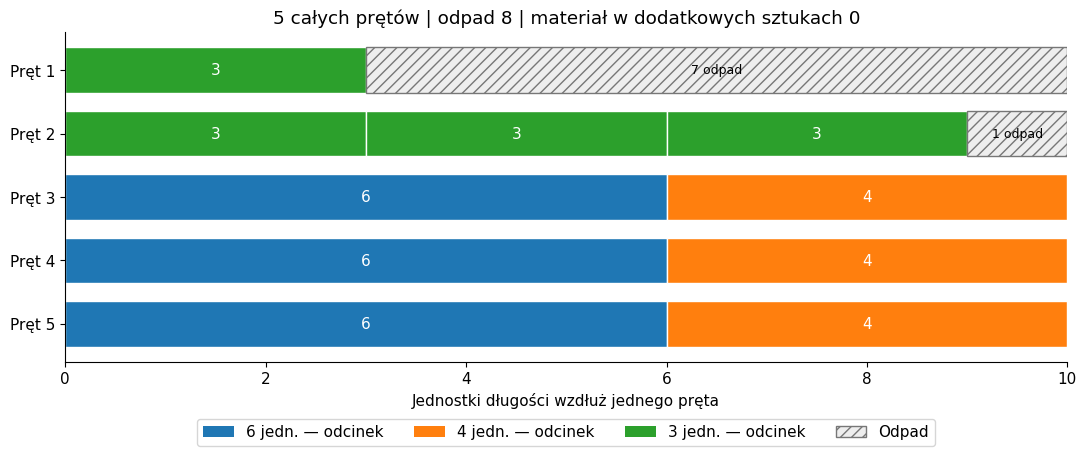

Bilans materiału: 5 × 10 = 42 zamówiony + 0 materiał w dodatkowych sztukach + 8 odpad


In [15]:
def plot_cutting(result):
    """Wyświetl fizyczny układ cięcia całkowitoliczbowego wyniku solve_cutting.

    result zawiera długości prętów i odcinków w tej samej jednostce, tabelę
    wzorców DataFrame i całkowite liczby prętów. Wypisuje komunikat przy braku
    optimum, wyniku ułamkowym lub zerowej liczbie prętów. Rozwija użyte wzorce
    na wiersze całych prętów; szerokości opisują długości, a kreskowanie — odpad.
    Korzysta z globalnych plt i Patch. Wyświetla rysunek oraz bilans materiału;
    zwraca None."""
    if result["status"] != "Optimal":
        print("Brak dopuszczalnego planu rozkroju do narysowania. Status:", result["status"])
        return
    if not result["integer"]:
        print("Ułamkowe pręty nie mają fizycznego diagramu rozkroju. Najpierw rozwiąż model całkowitoliczbowy.")
        return
    lengths, stock = result["lengths"], result["stock_length"]
    colors = plt.get_cmap("tab10").colors
    # Rozwiń DataFrame wzorców tak, aby każdy narysowany wiersz był jednym kupionym prętem.
    expanded = [row.pieces for row in result["plan"].itertuples() for _ in range(int(row.bars))]
    if not expanded:
        print("Zerowe zapotrzebowanie: pręty nie są potrzebne.")
        return
    fig, ax = plt.subplots(figsize=(11, max(3.5, 0.55 * len(expanded) + 2)))
    # Przesuwaj left wzdłuż pręta po narysowaniu odcinka; pozostała część to odpad.
    for row, pattern in enumerate(expanded):
        left = 0
        for i, (count, length) in enumerate(zip(pattern, lengths)):
            for _ in range(count):
                ax.barh(row, length, left=left, height=0.72, color=colors[i], edgecolor="white")
                ax.text(left + length / 2, row, str(length), ha="center", va="center", color="white")
                left += length
        assert left <= stock
        if left < stock:
            ax.barh(row, stock - left, left=left, height=0.72,
                    color="#eeeeee", edgecolor="#777777", hatch="///")
            ax.text((left + stock) / 2, row, f"{stock-left} odpad", ha="center", va="center", fontsize=9)
    ax.set_yticks(range(len(expanded)), [f"Pręt {i+1}" for i in range(len(expanded))])
    ax.invert_yaxis()
    ax.set(xlim=(0, stock), xlabel="Jednostki długości wzdłuż jednego pręta",
           title=f"{len(expanded)} całych prętów | odpad {result['trim']:g} | materiał w dodatkowych sztukach {result['extra_material']:g}")
    # Użyj tych samych kolorów w legendzie i sprawdź łączny materiał pod diagramem.
    legend = [Patch(facecolor=colors[i], label=f"{length} jedn. — odcinek") for i, length in enumerate(lengths)]
    legend.append(Patch(facecolor="#eeeeee", edgecolor="#777777", hatch="///", label="Odpad"))
    ax.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)
    plt.tight_layout()
    plt.show()
    ordered_material = sum(d * length for d, length in zip(result["demand"], lengths))
    print(f"Bilans materiału: {result['bars']:g} × {stock} = {ordered_material} zamówiony + "
          f"{result['extra_material']:g} materiał w dodatkowych sztukach + {result['trim']:g} odpad")

plot_cutting(cutting_ip)

### Zadanie 3 — zmień zapotrzebowanie lub długość pręta

**Przewidź:** jakie nowe wzorce będą możliwe, jeśli długość pręta wzrośnie z 10 do 11? Czy większa długość surowca może zwiększyć minimalną liczbę prętów przy wszystkich innych założeniach bez zmian?

Porównaj granicę LP, plan całkowitoliczbowy i wizualny bilans materiału. Po zmianie długości pręta **generuj wzorce na nowo**: użycie starej listy ukryłoby nowe możliwości.

**Zapisz:** długość pręta, zapotrzebowanie na odcinki, granicę LP, całkowitą liczbę prętów, odpad i dodatkowe sztuki. **Rekomendacja:** załóż, że pręt długości 11 kosztuje o 10% więcej niż pręt długości 10. Który kupisz dla zamówienia bazowego? Porównaj `bars × price_per_bar` — liczbę prętów razy cenę jednego pręta — a nie sam odpad.

,stock_length,status,LP_bars,integer_bars,trim,extra_material
0,9,Optimal,4.833333,5.0,3.0,0.0
1,10,Optimal,4.333333,5.0,8.0,0.0
2,11,Optimal,4.333333,5.0,13.0,0.0
3,12,Optimal,3.500000,4.0,6.0,0.0


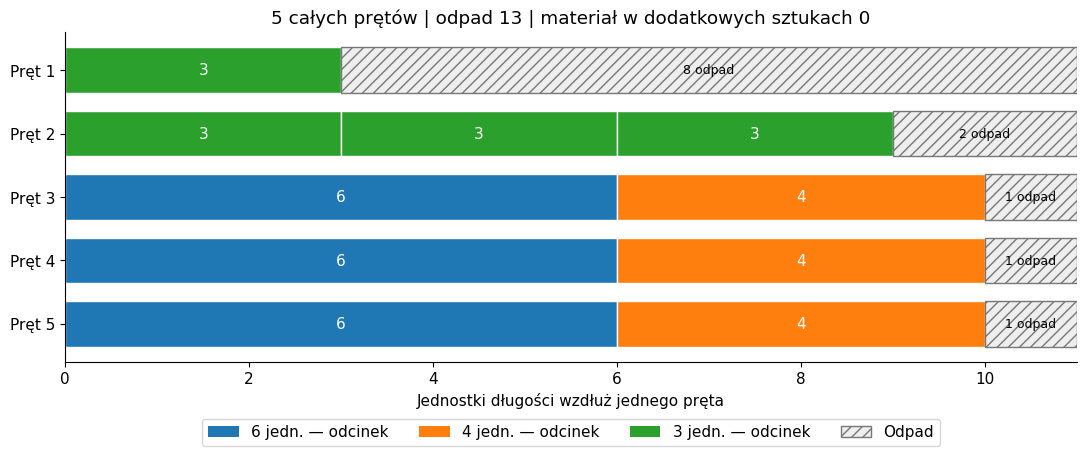

Bilans materiału: 5 × 11 = 42 zamówiony + 0 materiał w dodatkowych sztukach + 13 odpad
Zbyt krótki pręt: Infeasible
Brak dopuszczalnego planu rozkroju do narysowania. Status: Infeasible


In [16]:
# Generuj wszystkie wzorce dla każdej długości surowca; porównaj LP i wynik całkowity.
cutting_scenarios = []
for stock in [9, 10, 11, 12]:
    lower = solve_cutting(stock_length=stock, integer=False)
    whole = solve_cutting(stock_length=stock)
    cutting_scenarios.append({"stock_length": stock, "status": whole["status"],
                              "LP_bars": lower["bars"], "integer_bars": whole["bars"],
                              "trim": whole["trim"], "extra_material": whole["extra_material"]})
display(pd.DataFrame(cutting_scenarios))
plot_cutting(solve_cutting(stock_length=11))
# Celowo niedopuszczalny wariant: odcinek długości 6 nie mieści się w pręcie długości 5.
too_short = solve_cutting(stock_length=5)
print("Zbyt krótki pręt:", too_short["status"])
plot_cutting(too_short)

Mój scenariusz: Optimal | pręty: 5.0


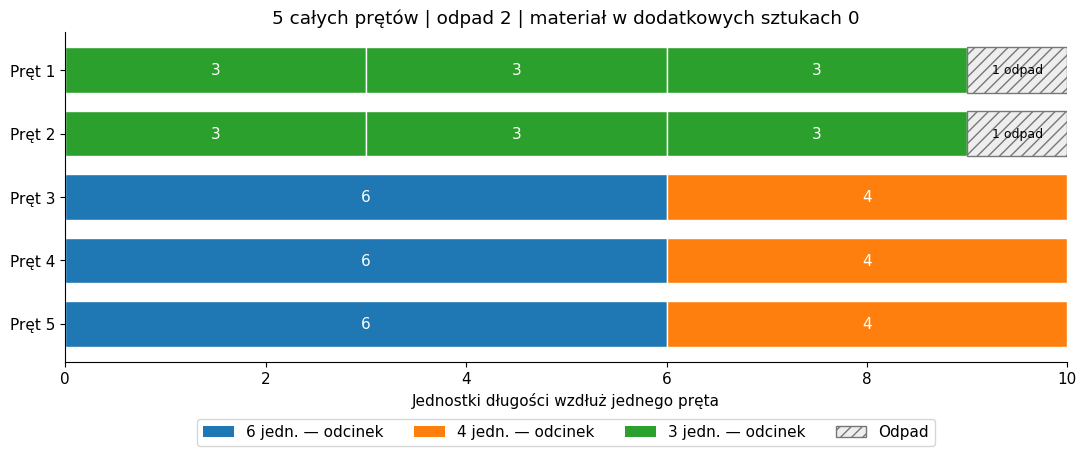

Bilans materiału: 5 × 10 = 48 zamówiony + 0 materiał w dodatkowych sztukach + 2 odpad


In [17]:
# Miejsce eksperymentu: zachowaj zwykłe wywołanie jako wariant bez widżetów.
my_cutting = solve_cutting(stock_length=10, demand=(3, 3, 6))
print("Mój scenariusz:", my_cutting["status"], "| pręty:", my_cutting["bars"])
plot_cutting(my_cutting)
# DO ZROBIENIA: porównaj exact_demand=True z domyślnym zapisem demand>=.
# DO ZROBIENIA: przygotuj tabelę zapotrzebowania na odcinki długości 3 od 0 do 10 sztuk.
# Wyjaśnij, dlaczego liczba całych prętów zmienia się skokowo.

## 4. Opcjonalne elementy interaktywne

Suwaki ponownie rozwiązują optymalizację i rysują fizyczny plan. Zacznij od przewidywania, zmień **jeden** element sterujący i wyjaśnij wynik. Jeśli widżety się nie pojawią, zmień argumenty zwykłego wywołania poniżej; model liczbowy i diagramy są identyczne.

**Zbuduj własną interakcję:** `cutting_explorer` jest funkcją obsługi zdarzenia, czyli *callbackiem*: jej parametry to dane wejściowe, a jej ciało rozwiązuje model, wyświetla tabelę i rysuje wykres. `widgets.interactive` dopasowuje nazwę suwaka do parametru funkcji i wywołuje ją po zmianie wartości. `continuous_update=False` czeka na puszczenie suwaka, co zapobiega wielokrotnemu rozwiązywaniu modelu podczas przeciągania.

Porównaj ciągłą, odcinkami liniową dolną granicę LP ze skokowymi zmianami planu całkowitoliczbowego przy wzroście zapotrzebowania. Obie krzywe odpowiadają na różne pytania.

Ta część jest opcjonalna i nie jest potrzebna do ukończenia ćwiczenia.

**Funkcja obsługi sterowania:** `cutting_explorer(stock_length, short_piece_demand)` przyjmuje dwie wartości sterujące, pozostawia pozostałe zapotrzebowania bez zmian, rozwiązuje LP i model całkowitoliczbowy oraz wyświetla tabelę wzorców i układ prętów. Zwraca słownik wyniku całkowitoliczbowego. Najpierw sprawdź ją zwykłym wywołaniem, a dopiero potem podłącz suwaki; korzystaj z wywołania także wtedy, gdy widżety są niedostępne.

Status: Optimal | granica LP: 4.3333333 | całe pręty: 5.0


,pattern_id,pieces,bars,trim_per_bar
0,0,"(0, 0, 1)",1,7
1,2,"(0, 0, 3)",1,1
2,9,"(1, 1, 0)",3,0


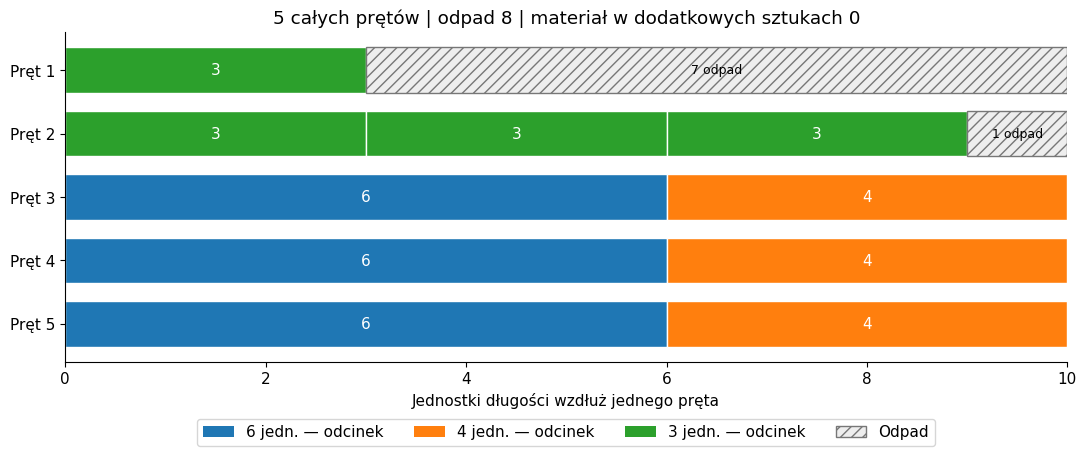

Bilans materiału: 5 × 10 = 42 zamówiony + 0 materiał w dodatkowych sztukach + 8 odpad


In [18]:
def cutting_explorer(stock_length=10, short_piece_demand=4):
    """Rozwiąż i wyświetl scenariusz rozkroju z dwóch wartości sterujących.

    stock_length domyślnie wynosi 10 jednostek długości; short_piece_demand
    wynosi 4 sztuki długości 3. Zapotrzebowanie na długości 6 i 4 pozostaje
    równe 3 sztukom każdej. Wywołuje solve_cutting dwa razy (model całkowity
    i LP) z domyślnymi długościami oraz globalnym CBC, a następnie wyświetla
    status, tabelę wzorców i układ przez plot_cutting. Zwraca słownik wyniku
    całkowitoliczbowego, więc działa także jako zwykła funkcja bez widżetów."""
    # Przelicz wartości sterowania na liczebności, rozwiąż oba modele i narysuj plan całych prętów.
    result = solve_cutting(stock_length=int(stock_length), demand=(3, 3, int(short_piece_demand)))
    lower = solve_cutting(stock_length=int(stock_length), demand=(3, 3, int(short_piece_demand)), integer=False)
    print("Status:", result["status"], "| granica LP:", lower["bars"], "| całe pręty:", result["bars"])
    if result["status"] == "Optimal":
        display(result["plan"])
    plot_cutting(result)
    return result

# Wariant zapasowy: działa w Colab także wtedy, gdy widżety są niedostępne.
explorer_example = cutting_explorer(stock_length=10, short_piece_demand=4)

In [19]:
# Opcjonalny interfejs: nazwy parametrów łączą elementy sterujące ze zwykłą funkcją powyżej.
try:
    import ipywidgets as widgets
    # Połącz nazwane elementy sterujące z parametrami funkcji o identycznych nazwach.
    controls = widgets.interactive(
        cutting_explorer,
        stock_length=widgets.IntSlider(value=10, min=6, max=14, step=1,
                                        description="Długość pręta", continuous_update=False),
        short_piece_demand=widgets.IntSlider(value=4, min=0, max=10, step=1,
                                             description="Popyt: dł. 3", continuous_update=False),
    )
    display(controls)
except (ImportError, RuntimeError) as error:
    print("Elementy sterujące są niedostępne. Użyj cutting_explorer(...).", type(error).__name__)

interactive(children=(IntSlider(value=10, continuous_update=False, description='Długość pręta', max=14, min=6)…

### Opcjonalne zadanie 4 — zbuduj wykres i rozbuduj sterowanie

1. W pętli wywołaj `solve_cutting(demand=(3, 3, d), integer=False)` i `solve_cutting(demand=(3, 3, d))` dla `d` od 0 do 10. Narysuj obie krzywe liczby prętów na wspólnych osiach z jednostkami i legendą. Wyjaśnij jeden przedział, w którym całkowita liczba prętów jest stała, a granica LP się zmienia.
2. Dodaj parametr `long_piece_demand` do `cutting_explorer`; przekaż go jako pierwszą składową `demand`. Dodaj `IntSlider` o **tej samej nazwie** do `widgets.interactive`. Zachowaj zwykłe wywołanie funkcji jako wariant bez widżetów.
3. Zmień funkcję obsługi zdarzenia tak, aby obok wykresu wyświetlała dodatkowe sztuki. Która forma prezentacji najłatwiej ujawnia rozbieżność z zamówieniem?

Zapisz zrzut ekranu własnego elementu sterującego lub wykresu i wskaż jedną decyzję, którą ułatwia użytkownikowi.

## 5. Opcjonalne rozszerzenia: od modelu dydaktycznego do bogatszego opisu

Wybierz **jedno** rozszerzenie. Zapisz zmienione równanie przed edycją kodu.

1. **Transport:** wprowadź maksimum 20 kg na North → Assembly. Czy to przepustowość trasy, czy limit zapasu magazynu? Dodaj $x_{\mathrm{North,Assembly}}\leq20$, rozwiąż ponownie i porównaj koszt.
2. **Sieć:** utwórz dodatkowe źródło lub węzeł pośredni. Podaż i zapotrzebowanie nadal muszą się bilansować; dodaj równanie zachowania w nowym węźle. Rozszerz funkcję diagramu o pozycję rysowania tego węzła.
3. **Rozkrój:** zachowaj reguły zapotrzebowania **≥** i minimalizuj odpad *wśród planów o minimalnej liczbie prętów*. Najpierw znajdź minimum $B^*$, następnie dodaj $\sum_p y_p=B^*$ i minimalizuj $\sum_p \mathrm{trim}_p y_p$. Porównaj odpad **i materiał w dodatkowych sztukach**: zmniejszenie odpadu może oznaczać tylko więcej niepotrzebnych odcinków. Wyjaśnij, dlaczego przy dokładnym zapotrzebowaniu i stałej liczbie identycznych prętów łączny odpad jest stały, więc drugi cel nie ma czego poprawiać.
4. **Rozkrój z rzazem:** zaproponuj spójną regułę liczenia cięć, np. każdy wyprodukowany odcinek zużywa swoją długość oraz jedną jednostkę rzazu. Zmień regułę dopasowania wzorców i oba sprawdzenia bilansu materiału. Wyjaśnij, jak twoja reguła traktuje ostatni koniec pręta.

Zachowaj sprawdzanie statusu. Zmieniony model może nie mieć rozwiązania dopuszczalnego; nigdy nie interpretuj wartości zmiennych zwróconych wtedy przez solver jako planu do wykonania.

## 6. Przekaż rekomendację operacyjną

Użyj tej krótkiej tabeli do zapisania **co najmniej jednego eksperymentu dla każdego problemu**:

| Problem | Przewidywanie | Jedna zmieniona dana | Status i wynik liczbowy | Wyjaśnienie | Rekomendowane działanie |
|---|---|---|---|---|---|
| Transport | ... | ... | ... | ... | ... |
| Przepływ w sieci | ... | ... | ... | ... | ... |
| Rozkrój | ... | ... | ... | ... | ... |

Dołącz jeden opisany diagram dostaw, jeden diagram wąskich gardeł i jeden układ rozkroju. Następnie odpowiedz:

- Gdzie nierówność opisywała dostępność, a gdzie równość — zachowanie materiału lub dokładne zamówienie?
- Dlaczego scenariusz bez rozwiązania dopuszczalnego był przydatny dla planisty?
- Które ilości były ciągłymi przepływami materiału, a które decyzje musiały być całkowitoliczbowe?
- Co pokazała relaksacja LP i czego **nie** dowiodła o użytecznym planie cięcia?
- Które założenie sprawdzisz przed przekazaniem tych planów rzeczywistemu operatorowi komórki robotycznej?

Rekomendacja powinna podawać ilości i jednostki, wyjaśniać kompromis i rozróżniać początkowe przewidywanie od zaobserwowanego wyniku optymalizacji.